# Solutions to the exercises of Chapter 2

**Chapter:** [2. Time integration: Euler, Velocity Verlet, and symplectic shadow Hamiltonians](../../notebooks/part1_nve_md/02_velocity_verlet_integrators.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
pos0, L0 = es.make_fcc_lattice(3, rho=0.72)
vel0 = es.init_velocities(len(pos0), T_target=1.2, rng=rng)
f_fn = lambda p, L: es.lj_forces_all_pairs(p, L, rc=2.5, shifted=True)

def run_nve_drift(dt: float, n_steps: int) -> tuple[np.ndarray, float]:
    p, v = pos0.copy(), vel0.copy()
    f, u, _ = f_fn(p, L0)
    E = np.zeros(n_steps)
    for k in range(n_steps):
        p, v, f, u, _, _ = es.velocity_verlet_step(p, v, f, dt, L0, f_fn)
        E[k] = 0.5 * float(np.sum(v * v)) + u
    return E, float(np.std(E))

Velocity Verlet energy-fluctuation scaling slope = 2.05 (expected 2.00)
Time-reversal position error after 50 steps = 8.88e-16


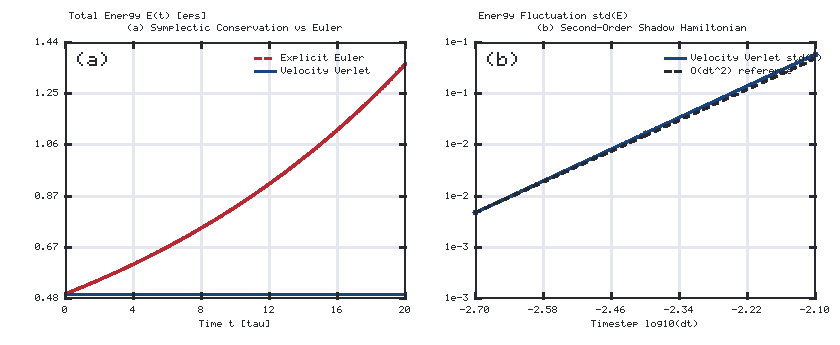

In [3]:
# 1. Verify O(dt^2) energy fluctuation scaling across dt = [0.002, 0.004, 0.008]
dts = np.array([0.002, 0.004, 0.008])
stds = []
for dt_v in dts:
    E_tr, s_e = run_nve_drift(float(dt_v), n_steps=int(0.4 / dt_v))
    stds.append(s_e)
stds = np.array(stds)
slope = float(np.polyfit(np.log(dts), np.log(stds), 1)[0])
print(f"Velocity Verlet energy-fluctuation scaling slope = {slope:.2f} (expected 2.00)")
assert 1.7 <= slope <= 2.3

# 2. Exact Time-Reversibility Test (25 steps forward, flip v -> -v, 25 steps back)
p, v = pos0.copy(), vel0.copy()
f, u, _ = f_fn(p, L0)
for _ in range(25):
    p, v, f, u, _, _ = es.velocity_verlet_step(p, v, f, 0.005, L0, f_fn)
v = -v
for _ in range(25):
    p, v, f, u, _, _ = es.velocity_verlet_step(p, v, f, 0.005, L0, f_fn)
rev_err = float(np.max(np.abs(es.minimum_image(p - pos0, L0))))
print(f"Time-reversal position error after 50 steps = {rev_err:.2e}")
assert rev_err < 1e-10

# 3. Diagnostic Figure: Euler vs Velocity Verlet on 1D Harmonic Oscillator & O(dt^2) scaling
t_ho = np.arange(0, 400) * 0.05
x_e, v_e = 1.0, 0.0
E_euler, E_vv = [], []
x_v, v_v = 1.0, 0.0
for _ in t_ho:
    x_e_new = x_e + 0.05 * v_e; v_e = v_e - 0.05 * x_e; x_e = x_e_new
    E_euler.append(0.5 * (x_e**2 + v_e**2))
    v_h = v_v - 0.025 * x_v; x_v = x_v + 0.05 * v_h; v_v = v_h - 0.025 * x_v
    E_vv.append(0.5 * (x_v**2 + v_v**2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(t_ho, E_euler, "r--", label="Explicit Euler")
ax1.plot(t_ho, E_vv, "b-", label="Velocity Verlet")
ax1.set_xlabel("Time t [tau]"); ax1.set_ylabel("Total Energy E(t) [eps]")
ax1.set_title("(a) Symplectic Conservation vs Euler Drift"); panel_label(ax1, "(a)")

ax2.loglog(dts, stds, "bo-", label="Velocity Verlet std(E)")
ax2.loglog(dts, stds[0] * (dts / dts[0])**2, "k--", label="O(dt^2) reference")
ax2.set_xlabel("Timestep log10(dt)"); ax2.set_ylabel("Energy Fluctuation std(E)")
ax2.set_title("(b) Second-Order Shadow Hamiltonian Scaling"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 2
p, v = pos0.copy(), vel0.copy()
f, _, _ = f_fn(p, L0)
for _ in range(100):
    p, v, f, _, _, _ = es.velocity_verlet_step(p, v, f, 0.004, L0, f_fn)
assert np.linalg.norm(np.sum(v, axis=0)) < 1e-12
# Exact shadow Hamiltonian check on harmonic oscillator (dt = 0.2)
dt_s = 0.2
xs, vs = 1.0, 0.0
E_std, E_shad = [], []
for _ in range(200):
    vh = vs - 0.5 * dt_s * xs; xs += dt_s * vh; vs = vh - 0.5 * dt_s * xs
    E_std.append(0.5 * (xs**2 + vs**2))
    E_shad.append(0.5 * vs**2 + 0.5 * (xs**2) * (1.0 - 0.25 * dt_s**2))
print(f"Ch 2 Exercises — std(E) = {np.std(E_std):.2e} vs. Shadow Hamiltonian std(E_tilde) = {np.std(E_shad):.2e}")
assert np.std(E_shad) < 1e-10

Ch 2 Exercises — std(E) = 1.76e-03 vs. Shadow Hamiltonian std(E_tilde) = 2.11e-16
